In [1]:
import random
import numpy as np
import torch
import os

def seed_everything(seed=20260322):
 random.seed(seed)
 os.environ['PYTHONHASHSEED'] = str(seed)
 np.random.seed(seed)

 try:
     torch.manual_seed(seed)
     torch.cuda.manual_seed(seed)
     torch.cuda.manual_seed_all(seed)
     torch.backends.cudnn.deterministic = True
     torch.backends.cudnn.benchmark = False
 except NameError:
     pass

seed_everything(20260322)

In [2]:
import pandas as pd

df_train = pd.read_csv("train_data.csv")
df_test = pd.read_csv("test_data.csv")

df_train.head()

,subtaskID,datapointID,answer
0,1,0,|967153686617|
1,1,1,|475237568072|
2,1,2,|554532815990|
3,1,3,|62700892530689|
4,1,4,|2065995398890|


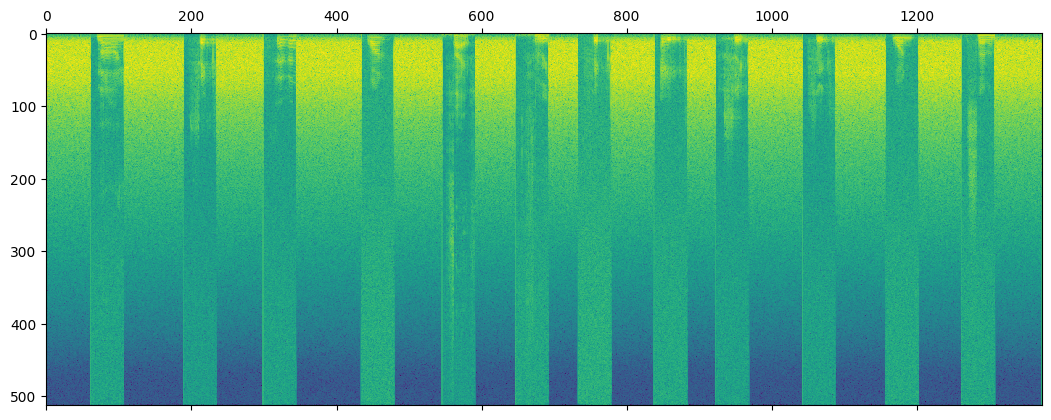

In [3]:
from scipy.io import wavfile
import scipy.signal as signal
import matplotlib.pyplot as plt

def get_spectrogram(wav_path):
    sr, data = wavfile.read(wav_path)
    _, _, Sxx = signal.spectrogram(data, sr, nperseg = 1024, noverlap = 500)
    Sxx = 10 * np.log10(Sxx + 1e-10)
    plt.matshow(Sxx)
    plt.show()

def get_waveform(wav_path):
    sr, data = wavfile.read(wav_path)
    plt.plot(data)
    plt.show()

get_spectrogram("train/0.wav")

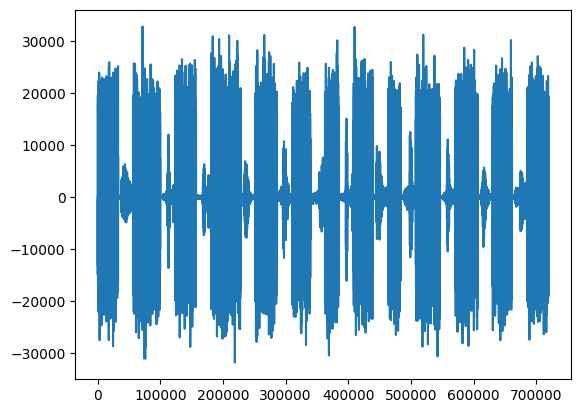

In [4]:
get_waveform("train/0.wav")

In [5]:
X = []
y = np.array(df_train.answer)

X_final = []

y.shape

(300,)

In [35]:
import tqdm

def get_spectrogram(wav_path):
    sr, data = wavfile.read(wav_path)
    _, _, Sxx = signal.spectrogram(data, sr, nperseg = 1024, noverlap = 500)
    Sxx = 10 * np.log10(Sxx + 1e-10)
    return Sxx

def get_waveform(wav_path):
    sr, data = wavfile.read(wav_path)
    return data

X1, X2 = [], []
for _, row in tqdm.tqdm(df_train.iterrows()):
    path = f'train/{row.datapointID}.wav'
    sxx = get_spectrogram(path)
    wav = get_waveform(path)
    X1.append(np.array(sxx).flatten())
    X2.append(np.array(wav).flatten())

X = np.hstack([np.array(X1), np.array(X2)])
X.shape

300it [00:15, 19.16it/s]


(300, 1424349)

In [36]:
X1, X2 = [], []
for _, row in tqdm.tqdm(df_test.iterrows()):
    path = f'test/{row.datapointID}.wav'
    sxx = get_spectrogram(path)
    wav = get_waveform(path)
    X1.append(np.array(sxx).flatten())
    X2.append(np.array(wav).flatten())

X_final = np.hstack([np.array(X1), np.array(X2)])
X_final.shape

200it [00:10, 18.28it/s]


(200, 1424349)

In [37]:
from sklearn.decomposition import TruncatedSVD
decom = TruncatedSVD(n_components=300, algorithm='randomized', n_iter=5)
X = decom.fit_transform(X)
X_final = decom.transform(X_final)

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score

model = LGBMClassifier(verbose=-1)
model.fit(X, y)

LGBMClassifier(verbose=-1)

In [39]:
preds = model.predict(X_final)

C:\Users\Ilie-Goga\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [40]:
df_preds = pd.DataFrame({
    "subtaskID": 1,
    "datapointID": df_test.datapointID,
    "answer": preds
})

df_preds

,subtaskID,datapointID,answer
0,1,0,|057783420502|
1,1,1,|2399168690730|
2,1,2,|7182933844338|
3,1,3,|6061455573285|
4,1,4,|2399168690730|
...,...,...,...
195,1,195,|057783420502|
196,1,196,|057783420502|
197,1,197,|6061455573285|
198,1,198,|7182933844338|


In [41]:
df_preds.to_csv("submission.csv", index=False)

In [42]:
df_preds.answer.value_counts()

answer
|057783420502|      95
|2399168690730|     33
|7182933844338|     31
|6061455573285|     28
|70090879529229|     8
|62119453700259|     4
|430148998426|       1
Name: count, dtype: int64